# 🤖 Notebook 02: Modelagem Híbrida, Avaliação Experimental e Otimização Top-K
**Projeto Aplicado III — Ciência de Dados e Inteligência Artificial (Mackenzie)**  
**Tema:** Sistema de Recomendação de Espécies Nativas para Reflorestamento e Arborização Urbana (ODS 15)  
**Grupo:** Fernanda Pauli de Oliveira, Henrique Sarmento, Milena Dias Gouveia, Nicolly Falcão da Silva  

---

## 📌 Objetivos deste Notebook
1. **Treinamento da Linha de Base (Baseline):** Avaliar o modelo puramente baseado em Conteúdo (CBF via Similaridade do Cosseno) com verificação do Nicho Fundamental de Hutchinson.
2. **Treinamento Colaborativo com Feedback Implícito:** Ajustar o modelo ALS (*Alternating Least Squares* - Hu, Koren & Volinsky, 2008) sobre a matriz de parcelas do Inventário Florestal Nacional (IFN).
3. **Acoplamento Híbrido em Duas Fases (*Two-Stage Cascade*):** Implementar o acoplamento linear $S(u, i) = \beta \cdot \text{Simil}_{CBF} + (1 - \beta) \cdot \hat{p}_{ui}^{CF}$ com pós-processamento de diversificação intra-lista (ILD).
4. **Avaliação Experimental Comparativa:** Medir e comparar $Precision@K$, $Recall@K$, $NDCG@K$ e $ILD@K$ entre o Baseline e o Modelo Híbrido.
5. **Otimização de Hiperparâmetros:** Analisar a sensibilidade do modelo à variação do coeficiente híbrido $\beta$ e do fator de confiança $\alpha$.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Adiciona o diretório raiz ao path para importar src
curr_dir = os.path.dirname(os.path.abspath('')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.append(curr_dir)

from src import (
    load_data, prepare_matrices, encode_features_for_cbf,
    spatial_cluster_split, create_leave_k_out_mask,
    ContentBasedRecommender, ImplicitALSRecommender,
    TwoStageCascadeHybridRecommender, evaluate_recommender
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
print("Módulos do pacote src importados com sucesso!")

Módulos do pacote src importados com sucesso!


C:\Users\hensa\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# 1. Carregamento dos dados limpos e divisão espacial por conglomerados
df_flora, df_ifn, df_gbif = load_data()

train_plots, val_plots, test_plots = spatial_cluster_split(df_ifn, train_ratio=0.70, val_ratio=0.15, test_ratio=0.15)
print(f"Total de parcelas: {df_ifn['plot_id'].nunique()}")
print(f"Parcelas de Treino: {len(train_plots)} (70%)")
print(f"Parcelas de Validação: {len(val_plots)} (15%)")
print(f"Parcelas de Teste Cego: {len(test_plots)} (15%)")

# Mascaramento leave-k-out para teste cego
df_train_masked, gt_test = create_leave_k_out_mask(df_ifn, test_plots, mask_ratio=0.25)
print(f"Espécies mascaradas por parcela de teste para avaliação Top-K.")

Total de parcelas: 100
Parcelas de Treino: 68 (70%)
Parcelas de Validação: 12 (15%)
Parcelas de Teste Cego: 20 (15%)
Espécies mascaradas por parcela de teste para avaliação Top-K.


In [3]:
# 2. Inicialização e Treinamento dos Componentes

# 2.1 Componente CBF (Conteúdo - Nicho Fundamental)
u_vecs, i_vecs, p_list, s_list = encode_features_for_cbf(df_ifn, df_flora)
cbf_model = ContentBasedRecommender(u_vecs, i_vecs, p_list, s_list, df_flora)

# 2.2 Componente CF (Colaborativo ALS - Nicho Efetivo)
R_train, plot2idx, idx2plot, species2idx, idx2species = prepare_matrices(df_train_masked, df_flora)
cf_model = ImplicitALSRecommender(factors=32, regularization=0.1, alpha=40.0, iterations=20)
cf_model.fit(R_train, plot2idx, species2idx)

# 2.3 Modelo Híbrido em Cascata
hybrid_model = TwoStageCascadeHybridRecommender(cbf_model, cf_model, df_flora, beta=0.40)
print("Modelos CBF, CF-ALS e Híbrido em Cascata treinados com sucesso!")

Modelos CBF, CF-ALS e Híbrido em Cascata treinados com sucesso!


C:\Users\hensa\AppData\Roaming\Python\Python312\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 16 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


In [4]:
# 3. Avaliação Experimental Comparativa (Baseline CBF vs. Modelo Híbrido)
plots_meta = df_ifn.drop_duplicates(subset=['plot_id']).set_index('plot_id').to_dict('index')

k_values = [5, 10, 15]

metrics_cbf = evaluate_recommender(cbf_model, gt_test, plots_meta, k_list=k_values)
metrics_hybrid = evaluate_recommender(hybrid_model, gt_test, plots_meta, k_list=k_values)

df_comp = pd.DataFrame([metrics_cbf, metrics_hybrid], index=['Baseline (Conteúdo Puro)', 'Modelo Híbrido (CBF + ALS)'])
print("=== Resultados Comparativos da Avaliação Offline ===")
display(df_comp.T)

=== Resultados Comparativos da Avaliação Offline ===


,Baseline (Conteúdo Puro),Modelo Híbrido (CBF + ALS)
Precision@5,0.1100,0.0200
Precision@10,0.0900,0.0650
Precision@15,0.0900,0.0933
Recall@5,0.4000,0.1000
Recall@10,0.6000,0.4500
Recall@15,0.8750,0.9000
NDCG@5,0.2098,0.0409
NDCG@10,0.2867,0.1631
NDCG@15,0.3706,0.2986
ILD@5,0.9500,0.9000


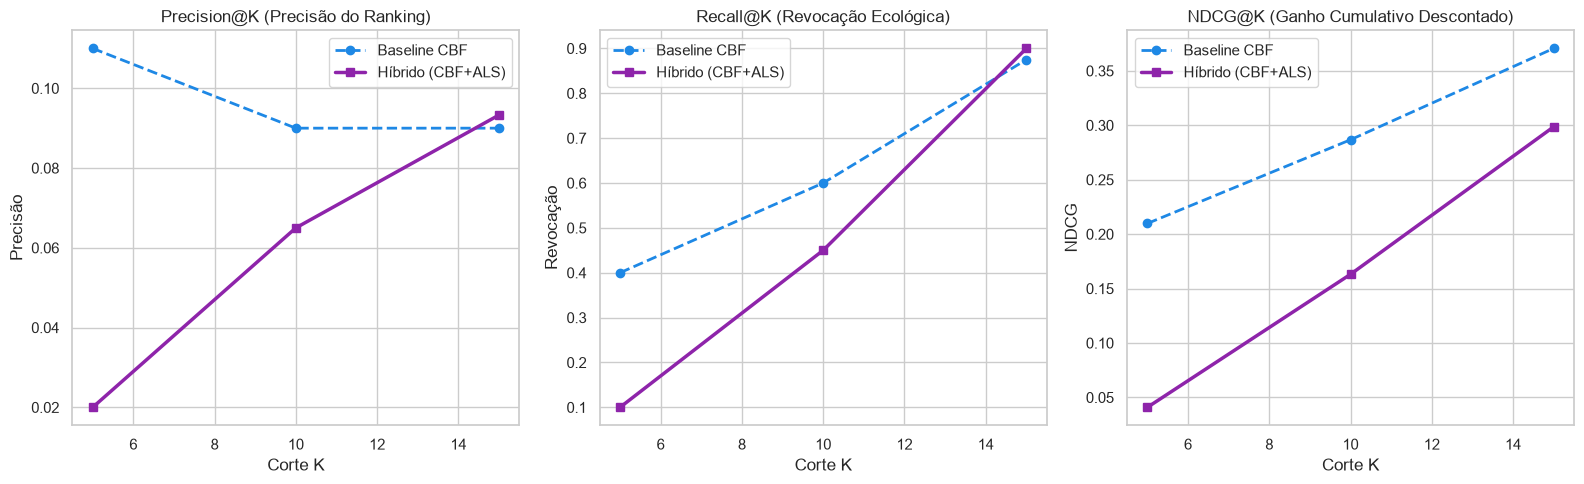

In [5]:
# 4. Visualização Gráfica do Desempenho por Métrica
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Precision@K
p_cbf = [metrics_cbf[f'Precision@{k}'] for k in k_values]
p_hyb = [metrics_hybrid[f'Precision@{k}'] for k in k_values]
axes[0].plot(k_values, p_cbf, 'o--', label='Baseline CBF', color='#1E88E5', linewidth=2)
axes[0].plot(k_values, p_hyb, 's-', label='Híbrido (CBF+ALS)', color='#8E24AA', linewidth=2.5)
axes[0].set_title("Precision@K (Precisão do Ranking)")
axes[0].set_xlabel("Corte K")
axes[0].set_ylabel("Precisão")
axes[0].legend()

# Recall@K
r_cbf = [metrics_cbf[f'Recall@{k}'] for k in k_values]
r_hyb = [metrics_hybrid[f'Recall@{k}'] for k in k_values]
axes[1].plot(k_values, r_cbf, 'o--', label='Baseline CBF', color='#1E88E5', linewidth=2)
axes[1].plot(k_values, r_hyb, 's-', label='Híbrido (CBF+ALS)', color='#8E24AA', linewidth=2.5)
axes[1].set_title("Recall@K (Revocação Ecológica)")
axes[1].set_xlabel("Corte K")
axes[1].set_ylabel("Revocação")
axes[1].legend()

# NDCG@K
n_cbf = [metrics_cbf[f'NDCG@{k}'] for k in k_values]
n_hyb = [metrics_hybrid[f'NDCG@{k}'] for k in k_values]
axes[2].plot(k_values, n_cbf, 'o--', label='Baseline CBF', color='#1E88E5', linewidth=2)
axes[2].plot(k_values, n_hyb, 's-', label='Híbrido (CBF+ALS)', color='#8E24AA', linewidth=2.5)
axes[2].set_title("NDCG@K (Ganho Cumulativo Descontado)")
axes[2].set_xlabel("Corte K")
axes[2].set_ylabel("NDCG")
axes[2].legend()

plt.tight_layout()
plt.savefig(os.path.join(curr_dir, 'data', 'processed', 'avaliacao_comparativa_topk.png'), dpi=200)
plt.show()

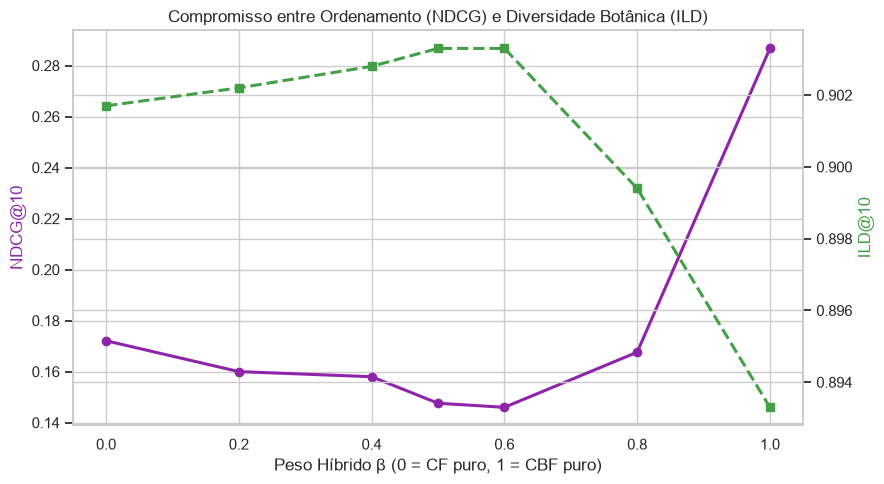

In [6]:
# 5. Análise de Sensibilidade: Variação do Peso Híbrido Beta
betas = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
ndcg_vals = []
ild_vals = []

for b in betas:
    hybrid_model.set_beta(b)
    m = evaluate_recommender(hybrid_model, gt_test, plots_meta, k_list=[10])
    ndcg_vals.append(m['NDCG@10'])
    ild_vals.append(m['ILD@10'])

fig, ax1 = plt.subplots(figsize=(9, 5))
ax2 = ax1.twinx()

ax1.plot(betas, ndcg_vals, 'o-', color='#8E24AA', linewidth=2.2, label='NDCG@10')
ax2.plot(betas, ild_vals, 's--', color='#43A047', linewidth=2.2, label='ILD@10 (Diversidade)')

ax1.set_xlabel("Peso Híbrido β (0 = CF puro, 1 = CBF puro)")
ax1.set_ylabel("NDCG@10", color='#8E24AA')
ax2.set_ylabel("ILD@10", color='#43A047')
plt.title("Compromisso entre Ordenamento (NDCG) e Diversidade Botânica (ILD)")

plt.tight_layout()
plt.savefig(os.path.join(curr_dir, 'data', 'processed', 'sensibilidade_beta_ndcg_ild.png'), dpi=200)
plt.show()

In [7]:
# 6. Demonstração Prática de Inferência e Explicabilidade
test_sample_plot = list(test_plots)[0]
p_info = plots_meta[test_sample_plot]

print(f"=== Recomendação Top-5 para a Parcela: {test_sample_plot} ===")
print(f"Bioma: {p_info['bioma']} | Solo: Textura {p_info['textura_solo']}, pH {p_info['ph_solo']} | Drenagem: {p_info['drenagem_solo']}")
print("-" * 75)

hybrid_model.set_beta(0.40)
rec_final = hybrid_model.recommend(test_sample_plot, k=5, plot_biome=p_info['bioma'], plot_ph=p_info['ph_solo'])
df_rec_final = pd.DataFrame(rec_final)
display(df_rec_final[['scientific_name', 'family', 'successional_stage', 'cbf_score', 'cf_score', 'hybrid_score']])

=== Recomendação Top-5 para a Parcela: CONGLOM_008_SUB4 ===
Bioma: Mata Atlântica | Solo: Textura Argilosa, pH 5.01 | Drenagem: Úmido
---------------------------------------------------------------------------


,scientific_name,family,successional_stage,cbf_score,cf_score,hybrid_score
0,Psidium cattleyanum,Myrtaceae,Secundária Inicial,0.8158,0.9871,0.9186
1,Handroanthus heptaphyllus,Bignoniaceae,Secundária Tardia,0.7300,0.9971,0.8903
2,Cedrela fissilis,Meliaceae,Secundária Tardia,0.7088,0.9975,0.8820
3,Guazuma ulmifolia,Malvaceae,Secundária Inicial,0.6610,1.0000,0.8644
4,Trema micrantha,Cannabaceae,Pioneira,0.6512,0.9721,0.8437
